Starting Skeletonization...
Skeletonization complete in 51 iterations.


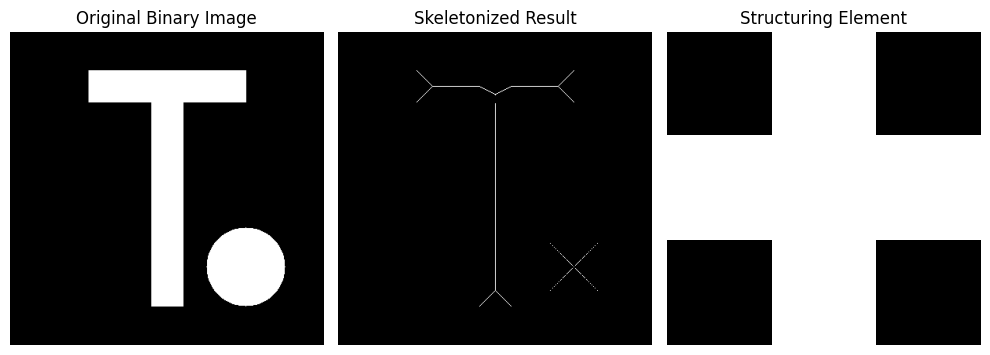

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Step 1: Create a Sample Binary Image ---
# We will create a blank black image
img = np.zeros((400, 400), dtype=np.uint8)

# Draw a "T" shape and a Circle to demonstrate skeletonization
# Vertical part of T
cv2.rectangle(img, (180, 50), (220, 350), 255, -1)
# Horizontal part of T
cv2.rectangle(img, (100, 50), (300, 90), 255, -1)
# A Circle
cv2.circle(img, (300, 300), 50, 255, -1)

# Make a copy for processing
img_copy = img.copy()

# --- Step 2: Initialize Skeleton Variables ---
# An empty black image to store the final skeleton
skeleton = np.zeros(img.shape, np.uint8)

# Define the Structuring Element (The "Brush")
# A 3x3 Cross shape works well for preserving connectivity
element = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

# --- Step 3: The Iterative Loop ---
print("Starting Skeletonization...")
iteration_count = 0

while True:
    # 1. Open the image (Erosion followed by Dilation)
    #    This smooths the object.
    eroded = cv2.erode(img_copy, element)
    temp = cv2.dilate(eroded, element) # This 'temp' is effectively Open(img)

    # 2. Subtract the Opened image from the Original (Current) image
    #    This isolates the 'skeletal' parts (the pixels that vanish during opening)
    temp = cv2.subtract(img_copy, temp)

    # 3. Add these parts to our Skeleton accumulator
    skeleton = cv2.bitwise_or(skeleton, temp)

    # 4. Update the image for the next step (Process the eroded version next)
    img_copy = eroded.copy()

    iteration_count += 1
    
    # 5. Break the loop if there is no object left
    if cv2.countNonZero(img_copy) == 0:
        break

print(f"Skeletonization complete in {iteration_count} iterations.")

# --- Step 4: Display Results ---
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.title("Original Binary Image")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Skeletonized Result")
plt.imshow(skeleton, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Structuring Element")
plt.imshow(element, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()